# Faster R-CNN, YOLO11s, RT-DETR-L and RetinaNet: final class-wise WBF ensemble (pipeline, tuned)

## Overview

Parent run: `pipeline-ensemble-extended` (P5b, run `dmnk1304/pipeline-ensemble-extended`, notebook `new-notebooks/pipeline-ensemble-extended.ipynb`): class-wise weighted boxes fusion (WBF, Solovyev et al., arXiv:1910.13302) of the saved detections of ten runs, full-val mAP@500 0.2904, 0.2901 on the 2,275 val frames outside quick-val, public LB 0.28856 (`SCOPE.md` F66). This notebook is brief X1 of `SCOPE.md` §6, a priority-2 run (§3.15). It trains nothing. It reads the saved predictions of finished runs (kernel sources) and fuses them. It uses no GPU: all of it runs on the CPU, and it works in a CPU-only Kaggle session. `uv run push-notebook` attaches a T4 accelerator by default and the notebook does not use it, so `gpu_name` is recorded as "none (CPU)" when no GPU is present. Its `val_predictions.json` and `submission.csv` are the input of X2 `pipeline-final-temporal` (final submission 1, `SCOPE.md` §3.14).

**What changes against P5b.** The priority-2 runs are exempt from the one-change rule (`SCOPE.md` §3.15), so every change is listed:
1. **Member set.** T1, P3 and T11 are left out (each changes the outside-quick-val mAP of P5b by at most ±0.0005 in its leave-one-out row, F68). Added: R3, T8, T6 (other families), P2 (frame offsets), the six P1 inference views of T3 and T7, C3 and its three views, and C4. 22 inputs in total (table below).
2. **Fusion settings fixed** at the P5b selection (F69): `conf_type = "box_and_model_avg"`, IoU threshold 0.7, `skip_box_thr` 0.001. There is no stage-1 grid.
3. **Weights.** The seven P5b members keep their P5b weights (`FIXED_WEIGHT_BY_LABEL`). Only the weights of the new members are searched on the quick-val frames, one pass in `SEARCH_ORDER`. Default grid {0.5, 1, 2} (`WBF_WEIGHT_GRID`). C4 and C3 use the wider grid {1, 2, 3, 4} (`WIDE_WEIGHT_GRID`) with a tie-break fixed before the run (decisions 17a and 20a of `SCOPE.md` §8, F97–F100, F113): the highest weight whose quick-val mAP@500 is within `C4_WEIGHT_TOLERANCE = 0.002` (`C3_WEIGHT_TOLERANCE = 0.002`) of the best weight of that member is selected. C4 is searched first, then C3 with C4 fixed, then the other new members with both fixed (search order chosen by the user on 2026-11-08).
4. **Ablation** by member group instead of one row per member (the P5b leave-one-out took 153 min, F70), on the 2,275 frames outside quick-val, after the submission is written (see Cost).

Decisions taken for this notebook: all six P1 views enter (decision 18, option a, chosen by the user on 2026-11-08); the optional small-box row of the brief is not run (dropped by the user on 2026-11-08); the legacy members stay (decision 14) and a current-protocol-only row is reported next to the final row.

| Label | Run (kernel source) | Family | Protocol | Input | mAP@500 | AP_small | Public LB | Weight |
|---|---|---|---|---|---|---|---|---|
| T2 | `dmnk1304/faster-rcnn-rpn-proposals` | two_stage | current | 1280 | 0.2290 | 0.1194 | 0.2332 | fixed 1 |
| T3 | `dmnk1304/faster-rcnn-giou` | two_stage | current | 1280 | 0.2371 | 0.1312 | 0.22569 | fixed 1 |
| T7 | `dmnk1304/yolo11s-1280-p2` | anchor_free | current | 1280 | 0.2165 | 0.1146 | 0.21419 | fixed 2 |
| FC5 | `dmnk1304/faster-cnn-5` | two_stage | legacy | 1280 | 0.2416 | 0.0994 | 0.21972 | fixed 1 |
| RTD | `dmnk1304/rt-detr-tuned-lr` | query | legacy | 640 | 0.2123 | 0.0889 | not recorded | fixed 1 |
| Y3 | `dmnk1304/yolo-3-1280` | anchor_free | legacy | 1280 | 0.1930 | 0.0900 | 0.19618 | fixed 1 |
| RN | `draklowell/retinanet` | one_stage_anchor | legacy | 1280 | 0.2055 | 0.0569 | 0.21420 | fixed 2 |
| C4 | `dmnk1304/yolo11s-p2-combined` | pipeline (YOLO11s P2) | current | 1280 | 0.2365 | 0.1266 | 0.28689 | {1, 2, 3, 4} |
| C3 | `draklowell/faster-rcnn-combined` | pipeline (Faster R-CNN) | current | 1280 | 0.2462 | 0.1261 | 0.24228 | {1, 2, 3, 4} |
| R3 | `draklowell/yolo11s-1280-rerun` | anchor_free | current | 1280 | 0.1921 | 0.1163 | not recorded | {0.5, 1, 2} |
| T8 | `draklowell/rtdetr-l-queries-500` | query | current | 640 | 0.2403 | 0.0980 | 0.26965 | {0.5, 1, 2} |
| T6 | `draklowell/retinanet-anchors-16-256` | one_stage_anchor | current | 1280 | 0.1901 | 0.0708 | 0.17558 | {0.5, 1, 2} |
| P2 | `dmnk1304/pipeline-frame-offsets` | pipeline (Faster R-CNN) | current | 1280 | 0.2429 | 0.1098 | 0.23211 | {0.5, 1, 2} |
| T3F, T3S16, T3S19 | `draklowell/pipeline-inference`: T3 flipped at 1280, long side 1600, long side 1920 | two_stage (view) | current | 1280 / 1600 / 1920 | not recorded | not recorded | not recorded | {0.5, 1, 2} |
| T7F, T7S16, T7S19 | `draklowell/pipeline-inference`: the same views of T7 | anchor_free (view) | current | 1280 / 1600 / 1920 | not recorded | not recorded | not recorded | {0.5, 1, 2} |
| C3F, C3S16, C3S19 | `draklowell/faster-rcnn-combined`: C3 flipped at 1280, long side 1600, long side 1920 | pipeline (view) | current | 1280 / 1600 / 1920 | 0.2425 / 0.2411 / 0.2289 | 0.1282 / 0.1238 / 0.1043 | not recorded | {0.5, 1, 2} |

Metrics: full val, `EXPERIMENTS.md` and the reports in `experiments/` (legacy rows are marked there with a dagger); C3 views from C3's `inference_views.csv`. P1 saved each view's detections but evaluated the views only fused with the plain view, so a single-view mAP of the P1 views is not recorded; it is computed here. The P5b output itself (`dmnk1304/pipeline-ensemble-extended`, `val_predictions.json`) is attached as a further kernel source, only for the "P5b reference" row of the ablation; it is not a member.

**Why** (`SCOPE.md` findings, numbers in `EXPERIMENTS.md`):
- Members of other families carry the most weight in P5b: removing T7 costs −0.0054 outside-quick-val mAP@500, RT-DETR −0.0039, RetinaNet −0.0038, while T1, P3 and T11 change it by at most ±0.0005 (F68). The added single runs extend the families: R3 (YOLO11s P3–P5, 0.1921, F72), T8 (RT-DETR-L, 500 queries, 0.2403, public LB 0.26965, bus AP 0.2510, F107–F110), T6 (the first current-protocol RetinaNet with a `submission.csv`, 0.1901, F81), P2 (Faster R-CNN on rotating frame offsets, 0.2429, F82).
- P1 views: on full val, T3 multi-scale + WBF is +0.0275 over T3 plain and T3 all views +0.0316 (7 of 7 clips); T7 all views +0.0223 (F101). The fused P1 file has LB − val −0.0163 (F104), and only the fused file was scored, so the test effect of the single views is unknown. The weight search decides each view's weight on quick-val.
- C4: public LB 0.28689, the highest single model, LB − val +0.0504 (F93). On labelled frames darkened to × 0.25 (the darkest test level) C4 keeps 0.0225 more mAP than T7 (F99), a condition val does not contain; this is the reason for the wider grid and the tie-break (decision 17a).
- C3: highest full-val mAP@500 of any single model, 0.2462 (F112); at brightness × 0.25 it keeps 0.0156 more than T3 on 7 of 7 clips, and 0.0285 more at 680 px with × 0.25 (F113); public LB 0.24228 (F114). C3's single views are each below its plain view on full val (F116); whether they help in the fusion is left to the weight search.
- Fixed settings: in P5b `box_and_model_avg` and `avg` were within 0.0002 on quick-val, IoU 0.7 was the best of {0.6, 0.7, 0.75}, and `skip_box_thr` 0.01 changed mAP by −0.0003 to +0.0009 (F69), so the grid is not searched again.

**Expectation.** Not predicted. The plan's guess (`SCOPE.md`, not measured) is that members of other families and data views add diversity; the size of the effect against P5b is not estimated. The decision rule of `SCOPE.md` §3.10 applies against P5b: full-val mAP@500 at least 0.01 above P5b and a per-clip AP delta of the same sign on at least 5 of the 7 val clips (P5b's `per_clip_ap.csv` and the P5b reference row of the ablation).

**Comparison with the legacy parent (legacy members).** P5b ran under the current protocol, and so did 18 of the 22 inputs (all except FC5, RTD, Y3, RN). The four legacy members ran under the older protocol (the dagger notes in `EXPERIMENTS.md`):
- `faster-cnn-5` and `retinanet`: no ignore fill (ignored areas trained as background); GT inside ignore regions not dropped; GT boxes under 1 px dropped; no cuDNN determinism; checkpoint chosen by quick-val mAP, as in the current protocol; submission boxes under 0.5 px dropped.
- `rt-detr-tuned-lr` and `yolo-3-1280`: no ignore fill; GT inside ignore regions not dropped; checkpoint = Ultralytics `best.pt` by fitness (mAP50-95) on all val frames, with no quick-val COCOeval; no `seed_everything` and no time guard; submission coordinates rounded to 1 decimal; `yolo-3-1280` does not clip its boxes to the image in its notebook (this notebook clips every member box to the image before the fusion).
- All four: result files without versions, speed protocol and other core keys; legacy output names (`val_predictions_<name>.json`, `submission.csv`).

RTD and Y3 selected their checkpoints on all val frames, so their val scores and every fusion that contains them are optimistic (decision 14). The delta of this ensemble over P5b therefore mixes the member set with the protocol difference of the legacy members, which both contain. The ablation row "final, current-protocol members only" is the validity check (`SCOPE.md` §8.14).

**Tuning and validity.**
- The new members' weights are searched on the 571 quick-val frames only (every 5th `val/` frame). Metrics are reported on all 2,846 val frames and on the 2,275 frames outside quick-val. The outside frames were not used by the weight search or by the fixed settings (P5b also tuned on quick-val). They were used to select the checkpoints of the two legacy Ultralytics members, so they are not free of selection for those members.
- The C4 and C3 tie-break can select a weight whose quick-val mAP@500 is up to 0.002 below that member's best weight; the selected weight, the val-best weight and weight 4 are all reported on the outside frames (ablation).
- Nothing is fitted on training data, and no model weights are learned. The settings are never tuned on the full val or on test.
- Every member was trained on `train/` clips only, so the fused val score is a hold-out score.
- Test detections are the fusion of the members' test files (top 500 per image), with the selected weights.

**Cost (estimate scaled from the P5b timings, not measured).** P5b took 52.6 min for ten member evaluations, 140.5 min for 38 quick-val trials and 15.3 min per leave-one-out fusion on the outside frames (F70); its fusion ran at 270.7 ms per frame for ten members, and the WBF time grows about linearly with the number of input boxes. With 22 inputs: member checks about 2 h, 33 quick-val trials (1 baseline, 3 for C4, 3 for C3, 2 for each of the 13 other new members) about 3.5–4 h, full-val and test fusion about 1–1.5 h, and 25–40 min per ablation row. The total of every row would pass the 12 h Kaggle limit, so:
- the Submission section runs before the ablation, so `val_predictions.json`, `result.json` and `submission.csv` exist even if the session runs short;
- `MAX_TRAIN_HOURS = 6` bounds the weight search (members not reached keep weight 1 and are listed in `result.json`);
- the ablation rows run in a fixed priority order, and a row is skipped when its projected end passes `MAX_SESSION_HOURS = 11` hours after the session start; skipped rows stay in the table with `status` "skipped: time budget" and are listed in `result.json`.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv`:
- `history.csv`: the weight-search trace (one row per evaluated weight, with quick-val mAP and AP50); there are no training epochs;
- `wide_grid_choice.csv`: for C4 and C3, the quick-val mAP of every weight of the wide grid, the val-best and the selected weight;
- `ensemble_ablation.csv`: each member alone (full val), the P5b reference, the cumulative member groups, the final ensemble, − T7, − T3, current-protocol members only, and C4 / C3 at their val-best weight and at 4;
- `fig_weight_search.png` and `fig_ensemble_ablation.png` (+ `.csv`).

`best.pt` and the training curves do not apply, because nothing is trained.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the protocol applies to a fusion run.**
- The split, the 56 training clips and the ignore handling belong to the members' training. This notebook only checks the frame counts. It does not fill ignore regions, because it trains nothing. Evaluation uses the same `val/annotations_coco.json` with `iscrowd=1`.
- There are no epochs. The "checkpoint" is the WBF setting with the best quick-val mAP@500, and `MAX_TRAIN_HOURS` bounds the weight search. The members' detections come from fp32 inference with score threshold 0.001 and at most 500 detections per frame; the fused output is capped at 500 detections per frame as well.
- Speed: the fusion runs on the CPU. `ms_per_image` in `result.json` is the sum of the members' recorded `ms_per_image` plus the fusion time per frame (see `speed_protocol`).

**How the protocol applies to a fusion run.**
- The split, the 56 training clips and the ignore handling belong to the members' training. This notebook only checks the frame counts. It does not fill ignore regions, because it trains nothing. Evaluation uses the same `val/annotations_coco.json` with `iscrowd=1`.
- There are no epochs. The "checkpoint" is the weight setting with the best quick-val mAP@500 (with the pre-registered tie-break for C4 and C3), and `MAX_TRAIN_HOURS` bounds the weight search. The members' detections come from fp32 inference with score threshold 0.001 and at most 500 detections per frame; the fused output is capped at 500 detections per frame as well.
- Speed: the fusion runs on the CPU. `ms_per_image` in `result.json` is the sum of the members' `ms_per_image` plus the fusion time per frame (see `speed_protocol`). P1 did not record a time per view, so the P1 views use the recorded time of their plain model scaled by the pixel ratio (size / 1280)²; this is an estimate.

**How weighted boxes fusion works**

Non-maximum suppression keeps one box of a group of overlapping boxes and drops the rest. WBF (Solovyev, Wang, Gabruseva, arXiv:1910.13302) uses all of them. The detections of all members are pooled per class (class-wise fusion, `SCOPE.md` F10) and sorted by score. Each box is compared with the fused boxes built so far: if the IoU with one of them is above `iou_thr`, it joins that cluster, and otherwise it starts a new one. A fused box is the average of the cluster's coordinates weighted by the box scores. Boxes with a score below `skip_box_thr` are dropped before the clustering.

With `conf_type = "box_and_model_avg"` (`ensemble-boxes` 1.0.10; the score of every box is first multiplied by its member's weight), the score of a fused box is the mean of the cluster's scores, rescaled by the cluster size over the summed weights of the cluster's boxes, and then by the summed weights of the distinct members present in the cluster over the sum of all member weights. A member's weight therefore sets both how much its boxes pull the fused coordinates and how much its presence raises the fused score. The fused detections of a frame are sorted by score and cut at 500, and the scores are clipped to [0, 1].

Requires: Kaggle GPU T4, Internet on.

## Setup

The only install is `ensemble-boxes` (MIT licence), pinned in the `kaggle` dependency group of `pyproject.toml`; it implements WBF. torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
%pip install -q ensemble-boxes==1.0.10

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import platform
import random
import time
from collections.abc import Callable
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure

from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

Seeding helper and the version banner. Nothing in this notebook uses the GPU, so it runs in a CPU-only Kaggle session, and `gpu_name` is recorded as "none (CPU)" when no GPU is present. `session_started` is the reference of the session time guard of the ablation (`MAX_SESSION_HOURS`).

In [3]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


session_started = time.time()
started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)"
package_versions = {
    "python": platform.python_version(),
    **{
        name: version(name)
        for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib", "ensemble-boxes"]
    },
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.18 | torch 2.11.0+cpu | torchvision 0.26.0+cpu | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | ensemble-boxes 1.0.10 | GPU: none (CPU)


## Config

Deviations from the single-run notebooks and from P5b, with reasons:
- `SOURCE_KERNELS` and `KERNEL_INPUT_ROOT`: the members' outputs are read from the kernel sources attached to this kernel; the mount path `/kaggle/input/notebooks/<owner>/<kernel>` worked in P5 (`SCOPE.md` F61). One kernel can provide several members (C3 and its views; the six P1 views), so the members are defined separately: `MODEL_MEMBER_KERNEL_BY_LABEL` for runs whose plain output is a member, `VIEW_SOURCE_BY_LABEL` for saved inference views as `(kernel, file stem, plain-model label, input long side)`. `MEMBER_LABELS` fixes the member order. `P5B_REFERENCE_KERNEL` is the P5b output, used only for the reference row.
- A missing file of a current-protocol member raises `FileNotFoundError`. A legacy member (`LEGACY_LABELS`) whose val or test file is missing is skipped, as in P5b, and the skip is shown in the member table and recorded in `result.json`.
- `LEGACY_VAL_FILE_BY_KERNEL` and `LEGACY_RECORD_BY_KERNEL` are copied from P5b: the legacy runs wrote `val_predictions_<name>.json`, and their result files lack core keys, so `mAP`, `ms_per_image`, `train_hours` and `imgsz` come from `EXPERIMENTS.md`.
- `RECORDED_VIEW_KERNELS`: kernels whose views have a recorded single-view `mAP` and `ms_per_image` in `inference_views.csv` (C3). The P1 views have none (see Overview).
- `FIXED_WEIGHT_BY_LABEL`: the P5b weights of the seven kept P5b members (F69). Every other member starts at `WBF_DEFAULT_WEIGHT` and is searched in `SEARCH_ORDER`.
- `ABLATION_GROUPS`: the cumulative member groups of the ablation, in the order of the brief; the last group completes the final member set. `ABLATION_REMOVED_LABELS`: the "− T7" and "− T3" rows (decisions 17a and 20b).

In [4]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = (
    "dmnk1304/faster-rcnn-rpn-proposals",
    "dmnk1304/faster-rcnn-giou",
    "dmnk1304/yolo11s-1280-p2",
    "dmnk1304/faster-cnn-5",
    "dmnk1304/rt-detr-tuned-lr",
    "dmnk1304/yolo-3-1280",
    "draklowell/retinanet",
    "dmnk1304/yolo11s-p2-combined",
    "draklowell/faster-rcnn-combined",
    "draklowell/yolo11s-1280-rerun",
    "draklowell/rtdetr-l-queries-500",
    "draklowell/retinanet-anchors-16-256",
    "dmnk1304/pipeline-frame-offsets",
    "draklowell/pipeline-inference",
    "dmnk1304/pipeline-ensemble-extended",
)
MODEL_MEMBER_KERNEL_BY_LABEL = {
    "T2": "dmnk1304/faster-rcnn-rpn-proposals",
    "T3": "dmnk1304/faster-rcnn-giou",
    "T7": "dmnk1304/yolo11s-1280-p2",
    "FC5": "dmnk1304/faster-cnn-5",
    "RTD": "dmnk1304/rt-detr-tuned-lr",
    "Y3": "dmnk1304/yolo-3-1280",
    "RN": "draklowell/retinanet",
    "C4": "dmnk1304/yolo11s-p2-combined",
    "C3": "draklowell/faster-rcnn-combined",
    "R3": "draklowell/yolo11s-1280-rerun",
    "T8": "draklowell/rtdetr-l-queries-500",
    "T6": "draklowell/retinanet-anchors-16-256",
    "P2": "dmnk1304/pipeline-frame-offsets",
}
VIEW_SOURCE_BY_LABEL = {
    "T3F": ("draklowell/pipeline-inference", "view_t3_s1280_flip", "T3", 1280),
    "T3S16": ("draklowell/pipeline-inference", "view_t3_s1600", "T3", 1600),
    "T3S19": ("draklowell/pipeline-inference", "view_t3_s1920", "T3", 1920),
    "T7F": ("draklowell/pipeline-inference", "view_t7_s1280_flip", "T7", 1280),
    "T7S16": ("draklowell/pipeline-inference", "view_t7_s1600", "T7", 1600),
    "T7S19": ("draklowell/pipeline-inference", "view_t7_s1920", "T7", 1920),
    "C3F": ("draklowell/faster-rcnn-combined", "view_c3_s1280_flip", "C3", 1280),
    "C3S16": ("draklowell/faster-rcnn-combined", "view_c3_s1600", "C3", 1600),
    "C3S19": ("draklowell/faster-rcnn-combined", "view_c3_s1920", "C3", 1920),
}
MEMBER_LABELS = (*MODEL_MEMBER_KERNEL_BY_LABEL, *VIEW_SOURCE_BY_LABEL)
P5B_REFERENCE_KERNEL = "dmnk1304/pipeline-ensemble-extended"
CURRENT_VAL_FILE_NAME = "val_predictions.json"
TEST_FILE_NAME = "submission.csv"
VIEW_RECORD_FILE_NAME = "inference_views.csv"
RECORDED_VIEW_KERNELS = ("draklowell/faster-rcnn-combined",)
VIEW_REFERENCE_SIZE = 1280

Legacy member files and records (copied from P5b), the fixed P5b weights, the search order and the ablation groups.

In [5]:
LEGACY_LABELS = ("FC5", "RTD", "Y3", "RN")
LEGACY_VAL_FILE_BY_KERNEL = {
    "dmnk1304/faster-cnn-5": "val_predictions_faster_rcnn_r50fpn_v2_1280.json",
    "dmnk1304/rt-detr-tuned-lr": "val_predictions_rtdetr_l_640_lr1e-4.json",
    "dmnk1304/yolo-3-1280": "val_predictions_yolo11s_1280.json",
    "draklowell/retinanet": "val_predictions_retinanet_r50fpn_v2_1280.json",
}
LEGACY_RECORD_BY_KERNEL: dict[str, dict[str, float]] = {
    "dmnk1304/faster-cnn-5": {"mAP": 0.2416, "ms_per_image": 198.3, "train_hours": 3.37, "imgsz": 1280},
    "dmnk1304/rt-detr-tuned-lr": {"mAP": 0.2123, "ms_per_image": 42.8, "train_hours": 3.34, "imgsz": 640},
    "dmnk1304/yolo-3-1280": {"mAP": 0.1930, "ms_per_image": 27.7, "train_hours": 2.71, "imgsz": 1280},
    "draklowell/retinanet": {"mAP": 0.2055, "ms_per_image": 113.8, "train_hours": 2.40, "imgsz": 1280},
}
FIXED_WEIGHT_BY_LABEL = {"T2": 1.0, "T3": 1.0, "T7": 2.0, "FC5": 1.0, "RTD": 1.0, "Y3": 1.0, "RN": 2.0}
SEARCH_ORDER = (
    "C4",
    "C3",
    "R3",
    "T8",
    "T6",
    "P2",
    "T3F",
    "T3S16",
    "T3S19",
    "T7F",
    "T7S16",
    "T7S19",
    "C3F",
    "C3S16",
    "C3S19",
)
ABLATION_GROUPS = (
    ("P5b members without T1, P3, T11", ("T2", "T3", "T7", "FC5", "RTD", "Y3", "RN")),
    ("+ R3, T8, T6", ("R3", "T8", "T6")),
    ("+ P2", ("P2",)),
    ("+ P1 views", ("T3F", "T3S16", "T3S19", "T7F", "T7S16", "T7S19")),
    ("+ C3, C3 views, C4 (final)", ("C3", "C3F", "C3S16", "C3S19", "C4")),
)
ABLATION_REMOVED_LABELS = ("T7", "T3")

Run identity, protocol constants, fusion settings, the weight grids, the time guards, figure settings, the member-set consistency check, the data-root check and the seed.
- `WBF_CONFIDENCE_TYPE`, `WBF_IOU_THRESHOLD`, `WBF_SKIP_BOX_THRESHOLD`: fixed at the P5b selection (F69); the library defaults are `avg`, 0.55 and 0.0.
- `WBF_WEIGHT_GRID` (default grid) and `WIDE_WEIGHT_GRID` with `C4_WEIGHT_TOLERANCE` / `C3_WEIGHT_TOLERANCE` (pre-registered tie-break, `WIDE_GRID_TOLERANCE_BY_LABEL`).
- `MEMBER_RESULT_TOLERANCE`: the largest allowed difference between a recorded `mAP` and the `mAP` recomputed here from the saved val detections (as in P5b).
- `MAX_TRAIN_HOURS = 6` bounds the weight search. `MAX_SESSION_HOURS = 11` bounds the ablation: a row runs only if its projected end, times `ABLATION_PROJECTION_MARGIN`, is within that many hours of the session start (the Kaggle limit is 12 h).

In [6]:
RUN_NAME = "pipeline-final"
MODEL_NAME = (
    "class-wise WBF (ensemble-boxes 1.0.10) of 22 saved runs and inference views: Faster R-CNN R50-FPN v2, "
    "YOLO11s, RT-DETR-L and RetinaNet"
)
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "pipeline-ensemble-extended"
CHANGED_PARAMS: list[str] = [
    "SOURCE_KERNELS",
    "MODEL_MEMBER_KERNEL_BY_LABEL",
    "VIEW_SOURCE_BY_LABEL",
    "FIXED_WEIGHT_BY_LABEL",
    "WBF_CONFIDENCE_TYPE",
    "WBF_IOU_THRESHOLD",
    "WBF_SKIP_BOX_THRESHOLD",
    "WIDE_WEIGHT_GRID",
    "SEARCH_ORDER",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_OUTSIDE_QUICK_VAL_FRAMES = 2275
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

WBF_CONFIDENCE_TYPE = "box_and_model_avg"
WBF_IOU_THRESHOLD = 0.7
WBF_SKIP_BOX_THRESHOLD = 0.001
WBF_DEFAULT_WEIGHT = 1.0
WBF_WEIGHT_GRID = (0.5, 1.0, 2.0)
WIDE_WEIGHT_GRID = (1.0, 2.0, 3.0, 4.0)
C4_WEIGHT_TOLERANCE = 0.002
C3_WEIGHT_TOLERANCE = 0.002
WIDE_GRID_TOLERANCE_BY_LABEL = {"C4": C4_WEIGHT_TOLERANCE, "C3": C3_WEIGHT_TOLERANCE}
MEMBER_RESULT_TOLERANCE = 5e-4
MAX_SESSION_HOURS = 11
ABLATION_PROJECTION_MARGIN = 1.2
SPEED_PROTOCOL = (
    "sum of the members' ms_per_image (recorded, each with its own speed protocol, Tesla T4, fp32; legacy and "
    "current-protocol members differ; P1 views estimated as their plain model's recorded ms times (size / 1280)^2) "
    "plus perf_counter around the WBF call per frame on the CPU in one process, all val frames, member inference "
    "excluded"
)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if set(SEARCH_ORDER) != set(MEMBER_LABELS) - set(FIXED_WEIGHT_BY_LABEL):
    raise ValueError("SEARCH_ORDER must list every member without a fixed P5b weight exactly once")
if sorted(label for _, labels in ABLATION_GROUPS for label in labels) != sorted(MEMBER_LABELS):
    raise ValueError("ABLATION_GROUPS must cover every member exactly once")
if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. The members trained on every `FRAME_STEP`-th frame of each `train/` clip; this notebook lists the same split only to check the counts of the protocol. Validation uses every `val/` frame, and quick validation (the tuning set) every `QUICK_VAL_STEP`-th one.

In [7]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth of the val split comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded from the GT arrays used by the analyses. The COCOeval itself reads the same file, so ignore regions are handled as `iscrowd=1`. The training-side helpers (ignore boxes of training frames, mean fill) are not needed here: the members applied them when they trained, and this notebook trains nothing.

In [8]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key

Apply the helper to the val split, and index the val and test frames: image ids, image sizes (the fusion works on boxes normalised by the image size) and the key lists. The frames outside quick-val (2,275 frames) are the val frames that the fusion tuning never sees. The test frames come from `test_images.csv`; the competition data has no `sample_submission.csv`.

In [9]:
val_images, val_targets_by_key = load_ground_truth("val")
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
key_by_val_image_id = {image_id: key for key, image_id in val_image_id_by_key.items()}
val_size_by_key = {
    key: (width, height) for key, width, height in val_images.select("frame_key", "width", "height").iter_rows()
}
val_keys = val_frames["frame_key"].to_list()
quick_val_keys = quick_val_frames["frame_key"].to_list()
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_keys]
quick_val_key_set = set(quick_val_keys)
outside_quick_val_keys = [key for key in val_keys if key not in quick_val_key_set]
outside_quick_val_image_ids = [val_image_id_by_key[key] for key in outside_quick_val_keys]
require_count("outside quick-val frames", len(outside_quick_val_keys), EXPECTED_OUTSIDE_QUICK_VAL_FRAMES)
val_clips = sorted(val_frames["clip"].unique().to_list())

test_images = pl.read_csv(DATA_ROOT / "test_images.csv").with_columns(
    frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
)
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_keys = test_images["frame_key"].to_list()
test_key_by_image_id = dict(test_images.select("image_id", "frame_key").iter_rows())
test_size_by_key = {
    key: (width, height) for key, width, height in test_images.select("frame_key", "width", "height").iter_rows()
}
print(
    f"val GT frames {len(val_targets_by_key)} | outside quick-val {len(outside_quick_val_keys)} "
    f"| test frames {len(test_keys)} | val clips {len(val_clips)}"
)

val GT frames 2846 | outside quick-val 2275 | test frames 3811 | val clips 7


Evaluation helpers, copied from the single-run notebooks: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing. `FrameDetections` is `(boxes, scores, class_ids)` with boxes `xyxy` in original pixels, float scores and 0-based class ids.

In [10]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [11]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the detections are filtered to the clip's frames and evaluated against the same ground truth. `evaluate_detections` runs the whole chain for one set of detections and returns the headline metrics, on all val frames or on a given subset of image ids.

In [12]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


def evaluate_detections(
    detections_by_key: dict[str, FrameDetections], image_ids: list[int] | None = None
) -> dict[str, float]:
    predictions = to_coco_results(detections_by_key, val_image_id_by_key)
    return summarise_metrics(evaluate_coco(val_ground_truth, predictions, image_ids))

Independent evaluations (one WBF setting, one member, one removed member) run one after another in the main process. A forked process pool hung on Kaggle in P5 (polars is multi-threaded, and forking it can deadlock), so the evaluations are sequential, and each job prints its run time.

In [13]:
def run_jobs[Job](function: Callable[[Job], dict[str, float]], jobs: list[Job]) -> list[dict[str, float]]:
    results = []
    for index, job in enumerate(jobs, start=1):
        job_started = time.time()
        results.append(function(job))
        print(f"job {index}/{len(jobs)} | {(time.time() - job_started) / 60:.1f} min", flush=True)
    return results

Member predictions. Each source kernel must have finished and must be attached as a kernel source; its files are read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`. `list_member_files` gives a member's kernel, val file and test file: a run's plain output (`val_predictions.json`, or the legacy name, and `submission.csv`) or a saved view (`<stem>_val_predictions.json`, `<stem>_submission.csv`). For validation, the saved val file (COCO results format, at most 500 detections per frame) is turned into `(boxes, scores, class_ids)` per frame key; frames without detections get empty arrays. For test, the submission file (`class score x y w h` groups, top 500 per image) is parsed the same way, and groups with a zero width or height are dropped (the legacy Ultralytics notebooks rounded to 1 decimal); every member must cover all 3,811 test frames. Boxes stay in float64, so a single member round-trips through the COCO format without change.

Member records: a current-protocol run's `result.json` provides `mAP`, `ms_per_image`, `train_hours` and `imgsz`, and its `run` must equal the kernel slug; a legacy run takes them from `LEGACY_RECORD_BY_KERNEL`. A C3 view takes `mAP` and `ms_per_image` from C3's `inference_views.csv`. A P1 view has no recorded `mAP` (its record has no `mAP` key, so it is not checked) and its `ms_per_image` is its plain model's recorded value times (size / 1280)². Views add no training hours.

In [14]:
MEMBER_RECORD_KEYS = ("mAP", "ms_per_image", "train_hours", "imgsz")


def get_val_file_name(kernel: str) -> str:
    return LEGACY_VAL_FILE_BY_KERNEL.get(kernel, CURRENT_VAL_FILE_NAME)


def list_member_files(label: str) -> tuple[str, str, str]:
    if label in VIEW_SOURCE_BY_LABEL:
        kernel, stem, _, _ = VIEW_SOURCE_BY_LABEL[label]
        return kernel, f"{stem}_val_predictions.json", f"{stem}_submission.csv"
    kernel = MODEL_MEMBER_KERNEL_BY_LABEL[label]
    return kernel, get_val_file_name(kernel), TEST_FILE_NAME


def is_member_available(label: str) -> bool:
    kernel, val_file_name, test_file_name = list_member_files(label)
    return all((KERNEL_INPUT_ROOT / kernel / name).is_file() for name in (val_file_name, test_file_name))


def read_member_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_run_record(kernel: str) -> dict[str, float]:
    if kernel in LEGACY_RECORD_BY_KERNEL:
        return LEGACY_RECORD_BY_KERNEL[kernel]
    result = json.loads(read_member_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return {key: float(result[key]) for key in MEMBER_RECORD_KEYS}


def read_view_record(label: str) -> dict[str, float]:
    kernel, stem, plain_label, size = VIEW_SOURCE_BY_LABEL[label]
    if kernel not in RECORDED_VIEW_KERNELS:
        plain_record = read_run_record(MODEL_MEMBER_KERNEL_BY_LABEL[plain_label])
        return {
            "ms_per_image": plain_record["ms_per_image"] * (size / VIEW_REFERENCE_SIZE) ** 2,
            "train_hours": 0.0,
            "imgsz": float(size),
        }
    views = pl.read_csv(read_member_file(kernel, VIEW_RECORD_FILE_NAME)).filter(
        pl.col("val_file") == f"{stem}_val_predictions.json"
    )
    require_count(f"{label} rows in {VIEW_RECORD_FILE_NAME}", views.height, 1)
    return {
        "mAP": float(views["mAP"].item()),
        "ms_per_image": float(views["ms_per_image"].item()),
        "train_hours": 0.0,
        "imgsz": float(size),
    }


def read_member_record(label: str) -> dict[str, float]:
    if label in VIEW_SOURCE_BY_LABEL:
        return read_view_record(label)
    return read_run_record(MODEL_MEMBER_KERNEL_BY_LABEL[label])

Readers of the saved detections, copied from P5b with the file name passed in, because one kernel can hold several members.

In [15]:
def build_empty_detections() -> FrameDetections:
    return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=np.int64)


def load_member_val_detections(kernel: str, file_name: str) -> dict[str, FrameDetections]:
    predictions = (
        pl.DataFrame(
            json.loads(read_member_file(kernel, file_name).read_text()),
            schema={"image_id": pl.Int64, "category_id": pl.Int64, "bbox": pl.List(pl.Float64), "score": pl.Float64},
        )
        .select(
            "image_id",
            "score",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") > pl.col("x1")) & (pl.col("y2") > pl.col("y1")))
    )
    detections_by_key = {key: build_empty_detections() for key in val_keys}
    for (image_id,), frame in predictions.group_by("image_id"):
        detections_by_key[key_by_val_image_id[int(image_id)]] = (
            frame.select("x1", "y1", "x2", "y2").to_numpy(),
            frame["score"].to_numpy(),
            frame["class_id"].to_numpy(),
        )
    return detections_by_key


def load_member_test_detections(kernel: str, file_name: str) -> dict[str, FrameDetections]:
    submission = pl.read_csv(
        read_member_file(kernel, file_name), schema={"image_id": pl.String, "PredictionString": pl.String}
    ).with_columns(pl.col("PredictionString").fill_null(""))
    detections_by_key: dict[str, FrameDetections] = {}
    for image_id, prediction_string in submission.iter_rows():
        all_groups = np.array(prediction_string.split(), dtype=np.float64).reshape(-1, 6)
        groups = all_groups[(all_groups[:, 4] > 0) & (all_groups[:, 5] > 0)]
        boxes = np.stack([groups[:, 2], groups[:, 3], groups[:, 2] + groups[:, 4], groups[:, 3] + groups[:, 5]], axis=1)
        detections_by_key[test_key_by_image_id[image_id]] = (boxes, groups[:, 1], groups[:, 0].astype(np.int64))
    require_count(f"{kernel}/{file_name} test frames", len(detections_by_key), EXPECTED_TEST_FRAMES)
    return detections_by_key

Load the members and show one row per member. A legacy member with a missing val or test file is skipped (`status`), and all later steps use the loaded members only. `val_detections` and `test_detections` count the detections that enter the fusion; `recorded_mAP` is empty for the P1 views.

In [16]:
skipped_labels = [label for label in MEMBER_LABELS if label in LEGACY_LABELS and not is_member_available(label)]
member_labels = tuple(label for label in MEMBER_LABELS if label not in skipped_labels)
member_files = [list_member_files(label) for label in member_labels]
member_records = [read_member_record(label) for label in member_labels]
val_detections_by_member = [load_member_val_detections(kernel, val_file) for kernel, val_file, _ in member_files]
test_detections_by_member = [load_member_test_detections(kernel, test_file) for kernel, _, test_file in member_files]
member_table = pl.DataFrame(
    {
        "label": list(MEMBER_LABELS),
        "kernel": [list_member_files(label)[0] for label in MEMBER_LABELS],
        "val_file": [list_member_files(label)[1] for label in MEMBER_LABELS],
        "status": ["skipped: files missing" if label in skipped_labels else "loaded" for label in MEMBER_LABELS],
    }
).join(
    pl.DataFrame(
        {
            "label": list(member_labels),
            "recorded_mAP": [member_record.get("mAP") for member_record in member_records],
            "val_detections": [sum(len(item[1]) for item in member.values()) for member in val_detections_by_member],
            "test_detections": [sum(len(item[1]) for item in member.values()) for member in test_detections_by_member],
        },
        schema={
            "label": pl.String,
            "recorded_mAP": pl.Float64,
            "val_detections": pl.Int64,
            "test_detections": pl.Int64,
        },
    ),
    on="label",
    how="left",
)
member_table

label,kernel,val_file,status,recorded_mAP,val_detections,test_detections
str,str,str,str,f64,i64,i64
"""T2""","""dmnk1304/faster-rcnn-rpn-propo…","""val_predictions.json""","""loaded""",0.229,1422819,1898664
"""T3""","""dmnk1304/faster-rcnn-giou""","""val_predictions.json""","""loaded""",0.2371,1302843,1805941
"""T7""","""dmnk1304/yolo11s-1280-p2""","""val_predictions.json""","""loaded""",0.2165,1056149,1527200
"""FC5""","""dmnk1304/faster-cnn-5""","""val_predictions_faster_rcnn_r5…","""loaded""",0.2416,638003,793223
"""RTD""","""dmnk1304/rt-detr-tuned-lr""","""val_predictions_rtdetr_l_640_l…","""loaded""",0.2123,853800,1143300
…,…,…,…,…,…,…
"""T7S16""","""draklowell/pipeline-inference""","""view_t7_s1600_val_predictions.…","""loaded""",null,1069188,1610325
"""T7S19""","""draklowell/pipeline-inference""","""view_t7_s1920_val_predictions.…","""loaded""",null,1074763,1700500
"""C3F""","""draklowell/faster-rcnn-combine…","""view_c3_s1280_flip_val_predict…","""loaded""",0.2425,935028,1360642


Member check and single-member rows. Each loaded member's saved full-val detections are evaluated here (full-val COCOeval). Where a recorded `mAP` exists, the recomputed `mAP` must match it within `MEMBER_RESULT_TOLERANCE`; otherwise the notebook raises, because the attached files would not belong to the run it expects. The rows are the single-member rows of `ensemble_ablation.csv`.

In [17]:
def evaluate_single_member(member_index: int) -> dict[str, float]:
    return evaluate_detections(val_detections_by_member[member_index])


single_rows = run_jobs(evaluate_single_member, list(range(len(member_labels))))
for label, row, member_record in zip(member_labels, single_rows, member_records, strict=True):
    recorded_map = member_record.get("mAP")
    if recorded_map is not None and abs(row["mAP"] - recorded_map) > MEMBER_RESULT_TOLERANCE:
        raise ValueError(f"{label}: recomputed mAP {row['mAP']} differs from recorded {recorded_map}")
pl.DataFrame(
    {
        "label": list(member_labels),
        "recomputed_mAP": [row["mAP"] for row in single_rows],
        "recomputed_AP_small": [row["AP_small"] for row in single_rows],
        "recorded_mAP": [member_record.get("mAP") for member_record in member_records],
    },
    schema={
        "label": pl.String,
        "recomputed_mAP": pl.Float64,
        "recomputed_AP_small": pl.Float64,
        "recorded_mAP": pl.Float64,
    },
)

job 1/22 | 7.0 min
job 2/22 | 5.4 min
job 3/22 | 7.5 min
job 4/22 | 2.9 min
job 5/22 | 5.0 min
job 6/22 | 6.9 min
job 7/22 | 7.3 min
job 8/22 | 8.2 min
job 9/22 | 4.8 min
job 10/22 | 7.1 min
job 11/22 | 6.9 min
job 12/22 | 7.3 min
job 13/22 | 5.7 min
job 14/22 | 5.5 min
job 15/22 | 5.3 min
job 16/22 | 5.3 min
job 17/22 | 7.4 min
job 18/22 | 7.6 min
job 19/22 | 7.6 min
job 20/22 | 4.8 min
job 21/22 | 5.1 min
job 22/22 | 5.3 min


label,recomputed_mAP,recomputed_AP_small,recorded_mAP
str,f64,f64,f64
"""T2""",0.229,0.1194,0.229
"""T3""",0.2371,0.1312,0.2371
"""T7""",0.2165,0.1146,0.2165
"""FC5""",0.2416,0.0994,0.2416
"""RTD""",0.2123,0.0889,0.2123
…,…,…,…
"""T7S16""",0.2146,0.1281,null
"""T7S19""",0.2088,0.1241,null
"""C3F""",0.2425,0.1282,0.2425


## Model

The model of this run is the fusion function, with no learned weights (copied from P5b). `fuse_frame` normalises every member's boxes by the image size, clips them to [0, 1], calls `weighted_boxes_fusion` of `ensemble-boxes` with the setting's `conf_type`, sorts the result by score, keeps the top `MAX_DETECTIONS`, scales the boxes back to original pixels, clips them to the image and clips the scores to [0, 1]. Frames where no member has a detection give empty arrays. The library fuses per class, so detections of different classes are never merged (class-wise fusion, `SCOPE.md` F10). A `FusionSetting` is `(member weights, IoU threshold, skip_box_thr, confidence type)`. Here only the weights vary: the IoU threshold, `skip_box_thr` and the confidence type are the fixed Config values. The starting weights are the P5b weights for the kept P5b members and `WBF_DEFAULT_WEIGHT` for every new member.

In [18]:
type FusionSetting = tuple[tuple[float, ...], float, float, str]


def fuse_frame(
    member_detections: list[FrameDetections],
    size: tuple[int, int],
    setting: FusionSetting,
) -> FrameDetections:
    if all(len(scores) == 0 for _, scores, _ in member_detections):
        return build_empty_detections()
    weights, iou_threshold, skip_box_threshold, confidence_type = setting
    width, height = size
    scale = np.array([width, height, width, height], dtype=np.float64)
    boxes, scores, class_ids = weighted_boxes_fusion(
        [(boxes / scale).clip(0, 1) for boxes, _, _ in member_detections],
        [scores for _, scores, _ in member_detections],
        [class_ids for _, _, class_ids in member_detections],
        weights=list(weights),
        iou_thr=iou_threshold,
        skip_box_thr=skip_box_threshold,
        conf_type=confidence_type,
    )
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    return (
        (boxes[top_indices] * scale).clip(0, scale),
        scores[top_indices].clip(0.0, 1.0),
        class_ids[top_indices].astype(np.int64),
    )


def fuse_frames(
    detections_by_member: list[dict[str, FrameDetections]],
    keys: list[str],
    size_by_key: dict[str, tuple[int, int]],
    setting: FusionSetting,
) -> dict[str, FrameDetections]:
    return {
        key: fuse_frame([detections[key] for detections in detections_by_member], size_by_key[key], setting)
        for key in keys
    }


initial_weights = tuple(FIXED_WEIGHT_BY_LABEL.get(label, WBF_DEFAULT_WEIGHT) for label in member_labels)
print(
    f"WBF ensemble-boxes {package_versions['ensemble-boxes']} | {len(member_labels)} members "
    f"| {WBF_CONFIDENCE_TYPE} | IoU {WBF_IOU_THRESHOLD:g} | skip {WBF_SKIP_BOX_THRESHOLD:g} "
    f"| cap {MAX_DETECTIONS} detections per frame"
)

WBF ensemble-boxes 1.0.10 | 22 members | box_and_model_avg | IoU 0.7 | skip 0.001 | cap 500 detections per frame


## Training

There is no gradient training. This section searches the weights of the new members on the quick-val frames only (571 frames, every 5th `val/` frame): that set is the selection set of the run, as for the checkpoint selection of the members. The score of a weight setting is our COCOeval mAP@500 on the quick-val frames. Trials are evaluated one after another.

1. Baseline: the P5b weights for the kept P5b members, every new member at `WBF_DEFAULT_WEIGHT`.
2. Wide-grid members (C4, then C3, the first labels of `SEARCH_ORDER` that are in `WIDE_GRID_TOLERANCE_BY_LABEL`): every weight of `WIDE_WEIGHT_GRID` is scored with the other weights as they are (the current weight reuses the current score). Selected: the highest weight whose quick-val mAP@500 is at least the best one minus the member's tolerance (rounded to 4 decimals like the scores). The val-best weight (the lowest weight with the best score) is recorded too. The selected weight is kept even if its score is below the current one; this is the pre-registered rule of decisions 17a and 20a.
3. Default-grid members (the rest of `SEARCH_ORDER`): each in turn is tried at the other values of `WBF_WEIGHT_GRID`; a change is kept only if the quick-val mAP@500 rises strictly (the P5b rule). Ties go to the current weight.

One pass over the members. Before each member, the search stops if `MAX_TRAIN_HOURS` has passed; members not reached keep their current weight and are listed in `result.json` (`unsearched_members`). The trace is written to `history.csv` (`val_mAP` and `val_AP50` are the quick-val metrics of the trial; `is_final_weight` marks the trial whose weight was kept).

In [19]:
def score_quick_val(setting: FusionSetting) -> dict[str, float]:
    detections_by_key = fuse_frames(val_detections_by_member, quick_val_keys, val_size_by_key, setting)
    evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(detections_by_key, val_image_id_by_key), quick_val_image_ids
    )
    return {
        "val_mAP": round(compute_map_at_max_detections(evaluator), 4),
        "val_AP50": round(float(evaluator.stats[1]), 4),
    }


def pick_best_trial(scores: list[dict[str, float]]) -> int:
    return int(np.argmax([score["val_mAP"] for score in scores]))


def build_setting(weights: tuple[float, ...]) -> FusionSetting:
    return weights, WBF_IOU_THRESHOLD, WBF_SKIP_BOX_THRESHOLD, WBF_CONFIDENCE_TYPE


def replace_weight(weights: tuple[float, ...], label: str, weight: float) -> tuple[float, ...]:
    member_index = member_labels.index(label)
    return weights[:member_index] + (weight,) + weights[member_index + 1 :]


def is_search_time_over() -> bool:
    return (time.time() - tuning_started) / 3600 > MAX_TRAIN_HOURS


history_rows: list[dict[str, object]] = []
tuning_started = time.time()


def run_trials(
    searched_label: str, trial_weights: list[float], weight_tuples: list[tuple[float, ...]]
) -> list[dict[str, float]]:
    scores = run_jobs(score_quick_val, [build_setting(weights) for weights in weight_tuples])
    for trial_weight, weights, score in zip(trial_weights, weight_tuples, scores, strict=True):
        history_rows.append(
            {
                "step": len(history_rows) + 1,
                "member": searched_label,
                "weight": trial_weight,
                "weights": " ".join(f"{value:g}" for value in weights),
                **score,
                "minutes": round((time.time() - tuning_started) / 60, 1),
            }
        )
    return scores

Baseline trial and the split of `SEARCH_ORDER` into wide-grid and default-grid members.

In [20]:
current_weights = initial_weights
(baseline_score,) = run_trials("baseline", [WBF_DEFAULT_WEIGHT], [current_weights])
current_quick_val_map = baseline_score["val_mAP"]
wide_grid_labels = [label for label in SEARCH_ORDER if label in WIDE_GRID_TOLERANCE_BY_LABEL]
default_grid_labels = [label for label in SEARCH_ORDER if label not in WIDE_GRID_TOLERANCE_BY_LABEL]
unsearched_labels: list[str] = []
print(
    f"baseline quick-val mAP {current_quick_val_map:.4f} | wide grid {wide_grid_labels} "
    f"| default grid {len(default_grid_labels)} members"
)

job 1/1 | 8.8 min
baseline quick-val mAP 0.3079 | wide grid ['C4', 'C3'] | default grid 13 members


Wide-grid search for C4, then C3, with the pre-registered tie-break. How to read the table (`wide_grid_choice.csv`): one row per member and weight of `WIDE_WEIGHT_GRID`, with the quick-val mAP@500 of that weight given the weights fixed before it, the best score, the tolerance threshold, the val-best and the selected weight.

In [21]:
wide_grid_choice_by_label: dict[str, tuple[float, float]] = {}
wide_grid_rows: list[dict[str, object]] = []
for label in wide_grid_labels:
    if is_search_time_over():
        unsearched_labels.append(label)
        continue
    current_weight = current_weights[member_labels.index(label)]
    trial_weights = [weight for weight in WIDE_WEIGHT_GRID if weight != current_weight]
    trial_scores = run_trials(
        label, trial_weights, [replace_weight(current_weights, label, weight) for weight in trial_weights]
    )
    map_by_weight = {
        current_weight: current_quick_val_map,
        **{weight: score["val_mAP"] for weight, score in zip(trial_weights, trial_scores, strict=True)},
    }
    best_map = max(map_by_weight.values())
    threshold = round(best_map - WIDE_GRID_TOLERANCE_BY_LABEL[label], 4)
    val_best_weight = min(weight for weight, value in map_by_weight.items() if value == best_map)
    selected_weight = max(weight for weight, value in map_by_weight.items() if value >= threshold)
    current_weights = replace_weight(current_weights, label, selected_weight)
    current_quick_val_map = map_by_weight[selected_weight]
    wide_grid_choice_by_label[label] = (val_best_weight, selected_weight)
    for weight in sorted(map_by_weight):
        wide_grid_rows.append(
            {
                "member": label,
                "weight": weight,
                "val_mAP": map_by_weight[weight],
                "best_val_mAP": best_map,
                "threshold": threshold,
                "val_best_weight": val_best_weight,
                "selected_weight": selected_weight,
            }
        )
    print(
        f"member {label} | val-best weight {val_best_weight:g} | selected {selected_weight:g} "
        f"| quick-val mAP {current_quick_val_map:.4f}",
        flush=True,
    )
wide_grid_choice = pl.DataFrame(wide_grid_rows, infer_schema_length=None)
wide_grid_choice.write_csv(OUTPUT_DIR / "wide_grid_choice.csv")
wide_grid_choice

job 1/3 | 8.8 min
job 2/3 | 8.9 min
job 3/3 | 8.9 min
member C4 | val-best weight 4 | selected 4 | quick-val mAP 0.3102
job 1/3 | 8.8 min
job 2/3 | 8.9 min
job 3/3 | 8.8 min
member C3 | val-best weight 1 | selected 4 | quick-val mAP 0.3082


member,weight,val_mAP,best_val_mAP,threshold,val_best_weight,selected_weight
str,f64,f64,f64,f64,f64,f64
"""C4""",1.0,0.3079,0.3102,0.3082,4.0,4.0
"""C4""",2.0,0.3086,0.3102,0.3082,4.0,4.0
"""C4""",3.0,0.3098,0.3102,0.3082,4.0,4.0
"""C4""",4.0,0.3102,0.3102,0.3082,4.0,4.0
"""C3""",1.0,0.3102,0.3102,0.3082,1.0,4.0
"""C3""",2.0,0.3097,0.3102,0.3082,1.0,4.0
"""C3""",3.0,0.309,0.3102,0.3082,1.0,4.0
"""C3""",4.0,0.3082,0.3102,0.3082,1.0,4.0


Default-grid search: the other new members, one at a time, with C4 and C3 fixed.

In [22]:
for label in default_grid_labels:
    if is_search_time_over():
        unsearched_labels.append(label)
        continue
    current_weight = current_weights[member_labels.index(label)]
    trial_weights = [weight for weight in WBF_WEIGHT_GRID if weight != current_weight]
    candidates = [replace_weight(current_weights, label, weight) for weight in trial_weights]
    candidate_scores = run_trials(label, trial_weights, candidates)
    top_index = pick_best_trial(candidate_scores)
    is_accepted = candidate_scores[top_index]["val_mAP"] > current_quick_val_map
    if is_accepted:
        current_weights = candidates[top_index]
        current_quick_val_map = candidate_scores[top_index]["val_mAP"]
    print(
        f"member {label} | best weight {trial_weights[top_index]:g} "
        f"| quick-val mAP {candidate_scores[top_index]['val_mAP']:.4f}{' | accepted' if is_accepted else ''}",
        flush=True,
    )

job 1/2 | 8.9 min
job 2/2 | 8.8 min
member R3 | best weight 0.5 | quick-val mAP 0.3086 | accepted
job 1/2 | 8.9 min
job 2/2 | 9.1 min
member T8 | best weight 2 | quick-val mAP 0.3098 | accepted
job 1/2 | 9.0 min
job 2/2 | 8.8 min
member T6 | best weight 0.5 | quick-val mAP 0.3101 | accepted
job 1/2 | 8.8 min
job 2/2 | 9.2 min
member P2 | best weight 0.5 | quick-val mAP 0.3101
job 1/2 | 8.8 min
job 2/2 | 8.8 min
member T3F | best weight 0.5 | quick-val mAP 0.3105 | accepted
job 1/2 | 8.8 min
job 2/2 | 8.8 min
member T3S16 | best weight 0.5 | quick-val mAP 0.3108 | accepted
job 1/2 | 8.8 min
job 2/2 | 8.8 min
member T3S19 | best weight 2 | quick-val mAP 0.3117 | accepted
job 1/2 | 9.0 min
job 2/2 | 8.9 min
member T7F | best weight 0.5 | quick-val mAP 0.3115
job 1/2 | 8.9 min
job 2/2 | 8.9 min
member T7S16 | best weight 2 | quick-val mAP 0.3116
job 1/2 | 8.9 min
job 2/2 | 8.8 min
member T7S19 | best weight 2 | quick-val mAP 0.3117
job 1/2 | 8.7 min
job 2/2 | 8.0 min
member C3F | best weig

The selected setting and the search trace. `best_setting` is the tuned fusion used for validation, test and the ablation.

In [23]:
best_setting = build_setting(current_weights)
tuned_weights, tuned_iou_threshold, tuned_skip_box_threshold, tuned_confidence_type = best_setting
best_quick_val_map = current_quick_val_map
final_weight_by_label = dict(zip(member_labels, tuned_weights, strict=True))
tuning_hours = (time.time() - tuning_started) / 3600
history = pl.DataFrame(history_rows, infer_schema_length=None).with_columns(
    is_final_weight=pl.col("weight")
    == pl.col("member").replace_strict(final_weight_by_label, default=None, return_dtype=pl.Float64)
)
history.write_csv(OUTPUT_DIR / "history.csv")
print(
    f"tuning {tuning_hours:.2f} h | trials {history.height} | unsearched {unsearched_labels} "
    f"| quick-val mAP {best_quick_val_map:.4f}"
)

tuning 4.79 h | trials 33 | unsearched [] | quick-val mAP 0.3118


The tuned weight of every member (fixed P5b weights included).

In [24]:
pl.DataFrame(
    {
        "label": list(member_labels),
        "weight": list(tuned_weights),
        "is_searched": [label in SEARCH_ORDER and label not in unsearched_labels for label in member_labels],
    }
)

label,weight,is_searched
str,f64,bool
"""T2""",1.0,false
"""T3""",1.0,false
"""T7""",2.0,false
"""FC5""",1.0,false
"""RTD""",1.0,false
…,…,…
"""T7S16""",1.0,true
"""T7S19""",1.0,true
"""C3F""",1.0,true


Figures: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`.

In [25]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)

Weight-search figure. Left: quick-val mAP@500 of every trial in order (tick label = searched member and the weight tried), with the baseline as a dashed line. Right: quick-val mAP@500 against the weight for C4 and C3, with each member's tolerance threshold as a dotted line.

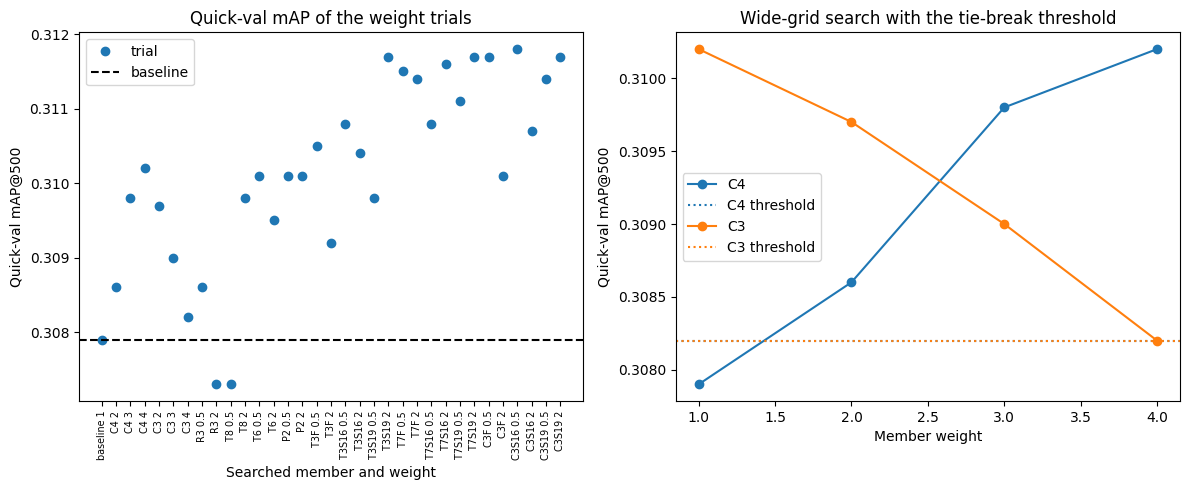

In [26]:
fig, (trace_ax, wide_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
trace_ax.plot(history["step"], history["val_mAP"], marker="o", linestyle="", label="trial")
trace_ax.axhline(baseline_score["val_mAP"], linestyle="--", color="black", label="baseline")
trace_ax.set_xticks(
    history["step"].to_list(),
    labels=[f"{member} {weight:g}" for member, weight in history.select("member", "weight").iter_rows()],
)
trace_ax.tick_params(axis="x", labelrotation=90, labelsize="x-small")
trace_ax.set_title("Quick-val mAP of the weight trials")
trace_ax.set_xlabel("Searched member and weight")
trace_ax.set_ylabel("Quick-val mAP@500")
trace_ax.legend()
for label in wide_grid_choice_by_label:
    rows = wide_grid_choice.filter(pl.col("member") == label)
    line = wide_ax.plot(rows["weight"], rows["val_mAP"], marker="o", label=label)
    wide_ax.axhline(rows["threshold"][0], linestyle=":", color=line[0].get_color(), label=f"{label} threshold")
wide_ax.set_title("Wide-grid search with the tie-break threshold")
wide_ax.set_xlabel("Member weight")
wide_ax.set_ylabel("Quick-val mAP@500")
wide_ax.legend()
save_figure(fig, "weight_search", history)

## Validation

The tuned fusion is applied to all val frames. Quick val is a subset of val and was used to search the weights (and to select the members' checkpoints), so this score is slightly optimistic. Speed protocol: the sum of the members' `ms_per_image` (recorded; estimated for the P1 views) plus `perf_counter` around the WBF call per frame (CPU, one process, all val frames, member inference excluded).

In [27]:
fusion_started = time.perf_counter()
val_detections_by_key = fuse_frames(val_detections_by_member, val_keys, val_size_by_key, best_setting)
fusion_ms_per_image = 1000 * (time.perf_counter() - fusion_started) / len(val_keys)
members_ms_per_image = sum(member_record["ms_per_image"] for member_record in member_records)
ms_per_image = members_ms_per_image + fusion_ms_per_image
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(
    f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} "
    f"| fusion {fusion_ms_per_image:.1f} ms/image | members {members_ms_per_image:.1f} ms/image"
)

1423000 detections | mAP 0.3117 | fusion 677.9 ms/image | members 4113.5 ms/image


Headline on the 2,275 val frames outside quick-val. The fusion tuning never saw these frames, so this number is not affected by the choice of the WBF setting. How to read this line: same detections and same COCOeval as above, restricted to `outside_quick_val_image_ids`. The checkpoints of the two legacy Ultralytics members were selected on all val frames, so the outside frames are not free of selection for those members.

In [28]:
outside_evaluator = evaluate_coco(val_ground_truth, val_predictions, outside_quick_val_image_ids)
outside_quick_val_metrics = summarise_metrics(outside_evaluator)
print(
    f"outside quick-val {len(outside_quick_val_keys)} frames | mAP {outside_quick_val_metrics['mAP']:.4f} "
    f"| AP_small {outside_quick_val_metrics['AP_small']:.4f} | AR500 {outside_quick_val_metrics['AR500']:.4f}"
)

outside quick-val 2275 frames | mAP 0.3124 | AP_small 0.1730 | AR500 0.5293


`result.json` writer: the core keys are checked before writing. Keys that do not apply to a fusion run (`imgsz`, `epochs_planned`, `epochs_run`, `best_epoch`, `batch`, `lr`) are `null`; `train_hours` is the wall-clock time of the weight search, and the GPU hours behind the members are in `members_train_hours`. The extra keys record the member set and files, the skipped members, the fixed settings, the tuned weights, the C4 and C3 choices and the outside-quick-val headline. The file is written again at the end of the ablation with the P5b reference and the skipped ablation rows.

In [29]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without the list and dict entries).

In [30]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": None,
    "epochs_planned": None,
    "epochs_run": None,
    "best_epoch": None,
    "batch": None,
    "lr": None,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(tuning_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "source_kernels": list(SOURCE_KERNELS),
    "member_labels": list(member_labels),
    "member_files": [f"{kernel}/{val_file} | {test_file}" for kernel, val_file, test_file in member_files],
    "skipped_members": skipped_labels,
    "member_imgsz": [int(member_record["imgsz"]) for member_record in member_records],
    "members_ms_per_image": round(members_ms_per_image, 1),
    "fusion_ms_per_image": round(fusion_ms_per_image, 1),
    "members_train_hours": round(sum(member_record["train_hours"] for member_record in member_records), 2),
    "wbf_confidence_type": tuned_confidence_type,
    "wbf_iou_threshold": tuned_iou_threshold,
    "wbf_skip_box_threshold": tuned_skip_box_threshold,
    "wbf_member_weights": list(tuned_weights),
    "wide_grid_val_best_weight": {label: choice[0] for label, choice in wide_grid_choice_by_label.items()},
    "wide_grid_selected_weight": {label: choice[1] for label, choice in wide_grid_choice_by_label.items()},
    "unsearched_members": unsearched_labels,
    "quick_val_mAP_tuned": best_quick_val_map,
    "outside_quick_val_frames": len(outside_quick_val_keys),
    "mAP_outside_quick_val": outside_quick_val_metrics["mAP"],
    "AP_small_outside_quick_val": outside_quick_val_metrics["AP_small"],
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if not isinstance(value, list | dict)}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,members_ms_per_image,fusion_ms_per_image,members_train_hours,wbf_confidence_type,wbf_iou_threshold,wbf_skip_box_threshold,quick_val_mAP_tuned,outside_quick_val_frames,mAP_outside_quick_val,AP_small_outside_quick_val
str,str,str,str,str,str,i64,null,null,null,null,null,null,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,f64,f64,f64,str,f64,f64,f64,i64,f64,f64
"""pipeline-final""","""new-notebooks/pipeline-final.i…","""class-wise WBF (ensemble-boxes…","""pipeline""","""tuned""","""pipeline-ensemble-extended""",42,null,null,null,null,null,null,4868,2846,5,"""per_image_mean_fill""",0.3117,0.3106,0.571,0.2975,0.1722,0.2766,0.5115,0.5301,4791.4,"""sum of the members' ms_per_ima…",4.79,"""none (CPU)""","""2026-11-08T13:31:28+00:00""","""2026-11-08T21:27:36+00:00""",4113.5,677.9,41.46,"""box_and_model_avg""",0.7,0.001,0.3118,2275,0.3124,0.173


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [31]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.3248,0.7297
1,"""bicycle""",0.2967,0.6366
2,"""car""",0.4635,0.7069
3,"""van""",0.3185,0.53
4,"""truck""",0.3906,0.6188
5,"""tricycle""",0.3442,0.6775
6,"""bus""",0.1961,0.2442
7,"""motor""",0.1589,0.4242


Per-clip AP of the fused detections (see the description above). How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [32]:
per_clip_ap = build_per_clip_ap(val_predictions)
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.294,0.6565,0.2727
"""uav0000117_02622_v""",349,0.3315,0.6051,0.06
"""uav0000137_00458_v""",233,0.3754,0.7416,0.0047
"""uav0000182_00000_v""",363,0.2486,0.5281,0.2006
"""uav0000268_05773_v""",978,0.2001,0.3325,0.0428
"""uav0000305_00000_v""",184,0.4051,0.5749,0.0484
"""uav0000339_00001_v""",275,0.338,0.5826,0.1081


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [33]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.3117,0.571,0.5301,0.8573
"""small""",21910,0.1722,0.4287,0.35,0.7652
"""medium""",79357,0.2766,0.5429,0.494,0.8373
"""large""",12865,0.5115,0.7867,0.7003,0.9775


## Submission

Fuse the members' test detections (their test files) with the tuned setting and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections. This section runs before the ablation, so the submission exists even if the session time guard cuts the ablation short.

In [34]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_detections_by_key = fuse_frames(test_detections_by_member, test_keys, test_size_by_key, best_setting)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[key])
    for image_id, key in test_images.select("image_id", "frame_key").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [35]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## Ensemble ablation

The question: what does each member give alone, how does the final ensemble compare with P5b, how much does each added member group contribute, and does the final ensemble depend on T7 and T3 once C4 and C3 are in it, on the legacy members, and on the C4 / C3 tie-break? Rows (all fused rows on the 2,275 frames outside quick-val; the weights are not re-tuned, every member keeps its final weight):
- each loaded member alone (its saved detections, no fusion), on all val frames, from the member check;
- P5b reference: P5b's own fused `val_predictions.json` (kernel source `dmnk1304/pipeline-ensemble-extended`, ten members incl. T1, P3, T11), no fusion here, on all val frames and on the outside frames; its full-val `mAP` is checked against its `result.json`;
- cumulative groups (`ABLATION_GROUPS`): the P5b members without T1, P3, T11, then + R3, T8, T6, then + P2, then + P1 views; the last group (+ C3, C3 views, C4) gives the final ensemble, which is computed once in Validation;
- final (tuned), on all val frames and on the outside frames;
- final without T7, final without T3 (decisions 17a, 20b);
- final, current-protocol members only (without FC5, RTD, Y3, RN; `SCOPE.md` §8.14);
- C4 at its val-best weight and at 4, C3 at its val-best weight and at 4, each only when it differs from the selected weight.

**Time guard.** The fused rows run in this priority order: P5b reference, current-protocol members only, − T7, − T3, the C4 / C3 weight rows, then the cumulative groups. Before each row, its time is projected from the measured fusion speed of the final full-val fusion per member and frame, times the row's member count and the 2,275 frames, plus the measured outside-frame COCOeval time, times `ABLATION_PROJECTION_MARGIN`. A row whose projected end passes `MAX_SESSION_HOURS` after the session start is skipped and kept in the table with `status` "skipped: time budget".

In [36]:
ablation_started = time.time()
p5b_reference_result = json.loads(read_member_file(P5B_REFERENCE_KERNEL, "result.json").read_text())
if p5b_reference_result["run"] != P5B_REFERENCE_KERNEL.split("/")[1]:
    raise ValueError(f"{P5B_REFERENCE_KERNEL}: result.json belongs to run {p5b_reference_result['run']}")
p5b_reference_detections = load_member_val_detections(P5B_REFERENCE_KERNEL, CURRENT_VAL_FILE_NAME)
p5b_reference_full = evaluate_detections(p5b_reference_detections)
if abs(p5b_reference_full["mAP"] - float(p5b_reference_result["mAP"])) > MEMBER_RESULT_TOLERANCE:
    raise ValueError(f"P5b reference: recomputed mAP {p5b_reference_full['mAP']} differs from recorded")
outside_evaluation_started = time.time()
p5b_reference_outside = evaluate_detections(p5b_reference_detections, outside_quick_val_image_ids)
outside_evaluation_seconds = time.time() - outside_evaluation_started
print(
    f"P5b reference | full mAP {p5b_reference_full['mAP']:.4f} | outside quick-val mAP "
    f"{p5b_reference_outside['mAP']:.4f} | outside COCOeval {outside_evaluation_seconds / 60:.1f} min"
)

P5b reference | full mAP 0.2904 | outside quick-val mAP 0.2901 | outside COCOeval 5.9 min


The planned fused rows in priority order: name and the weight of every member in the row. The cumulative groups must end with the final member set; the notebook raises otherwise.

In [37]:
def drop_labels(weight_by_label: dict[str, float], labels: tuple[str, ...]) -> dict[str, float]:
    return {label: weight for label, weight in weight_by_label.items() if label not in labels}


cumulative_rows: list[tuple[str, dict[str, float]]] = []
cumulative_labels: list[str] = []
for group_name, group_labels in ABLATION_GROUPS:
    cumulative_labels += [label for label in group_labels if label in final_weight_by_label]
    cumulative_rows.append((group_name, {label: final_weight_by_label[label] for label in cumulative_labels}))
if cumulative_rows[-1][1] != final_weight_by_label:
    raise ValueError("The last ablation group must complete the final member set")
weight_rows = [
    (f"final with {label} at weight {weight:g}", final_weight_by_label | {label: weight})
    for label, (val_best_weight, selected_weight) in wide_grid_choice_by_label.items()
    for weight in sorted({val_best_weight, max(WIDE_WEIGHT_GRID)} - {selected_weight})
]
planned_rows: list[tuple[str, dict[str, float]]] = [
    ("final, current-protocol members only", drop_labels(final_weight_by_label, LEGACY_LABELS)),
    *[(f"final without {label}", drop_labels(final_weight_by_label, (label,))) for label in ABLATION_REMOVED_LABELS],
    *weight_rows,
    *cumulative_rows[:-1],
]
pl.DataFrame(
    {
        "row": [name for name, _ in planned_rows],
        "n_members": [len(weight_by_label) for _, weight_by_label in planned_rows],
        "weights": [" ".join(f"{label} {weight:g}" for label, weight in row.items()) for _, row in planned_rows],
    }
)

row,n_members,weights
str,i64,str
"""final, current-protocol member…",18,"""T2 1 T3 1 T7 2 C4 4 C3 4 R3 0.…"
"""final without T7""",21,"""T2 1 T3 1 FC5 1 RTD 1 Y3 1 RN …"
"""final without T3""",21,"""T2 1 T7 2 FC5 1 RTD 1 Y3 1 RN …"
"""final with C3 at weight 1""",22,"""T2 1 T3 1 T7 2 FC5 1 RTD 1 Y3 …"
"""P5b members without T1, P3, T1…",7,"""T2 1 T3 1 T7 2 FC5 1 RTD 1 Y3 …"
"""+ R3, T8, T6""",10,"""T2 1 T3 1 T7 2 FC5 1 RTD 1 Y3 …"
"""+ P2""",11,"""T2 1 T3 1 T7 2 FC5 1 RTD 1 Y3 …"
"""+ P1 views""",17,"""T2 1 T3 1 T7 2 FC5 1 RTD 1 Y3 …"


Run the planned rows under the session time guard; one line per row.

In [38]:
def evaluate_outside(weight_by_label: dict[str, float]) -> dict[str, float]:
    member_indices = [member_labels.index(label) for label in weight_by_label]
    detections_by_key = fuse_frames(
        [val_detections_by_member[member_index] for member_index in member_indices],
        outside_quick_val_keys,
        val_size_by_key,
        build_setting(tuple(weight_by_label.values())),
    )
    return evaluate_detections(detections_by_key, outside_quick_val_image_ids)


member_frame_seconds = fusion_ms_per_image / 1000 / len(member_labels)
outside_metrics_by_row: dict[str, dict[str, float]] = {}
skipped_ablation_rows: list[str] = []
for name, weight_by_label in planned_rows:
    projected_seconds = ABLATION_PROJECTION_MARGIN * (
        len(weight_by_label) * member_frame_seconds * len(outside_quick_val_keys) + outside_evaluation_seconds
    )
    if (time.time() - session_started + projected_seconds) / 3600 > MAX_SESSION_HOURS:
        skipped_ablation_rows.append(name)
        print(f"{name} | skipped: projected {projected_seconds / 60:.0f} min passes {MAX_SESSION_HOURS} h", flush=True)
        continue
    row_started = time.time()
    outside_metrics_by_row[name] = evaluate_outside(weight_by_label)
    print(
        f"{name} | {len(weight_by_label)} members | outside mAP {outside_metrics_by_row[name]['mAP']:.4f} "
        f"| {(time.time() - row_started) / 60:.1f} min",
        flush=True,
    )

final, current-protocol members only | 18 members | outside mAP 0.3102 | 26.5 min
final without T7 | 21 members | outside mAP 0.3114 | 30.6 min
final without T3 | 21 members | outside mAP 0.3134 | 30.5 min
final with C3 at weight 1 | skipped: projected 38 min passes 11 h
P5b members without T1, P3, T11 | 7 members | outside mAP 0.2909 | 13.1 min
+ R3, T8, T6 | skipped: projected 21 min passes 11 h
+ P2 | skipped: projected 23 min passes 11 h
+ P1 views | skipped: projected 31 min passes 11 h


The ablation table. How to read this table: one row per configuration, in logical order (single members, P5b reference, cumulative groups, final, then the rows that change the final ensemble). `config` names it; `n_members` is the number of fused inputs (10 for the P5b reference). `*_full` columns are on all 2,846 val frames and `*_outside` columns on the 2,275 frames outside quick-val. `mAP` is AP@[.50:.95] at 500 detections per frame, `AP_small` is AP on objects under 32² px and `AR500` is the recall at 500 detections. `mAP_outside_delta_to_final` is the row minus the final ensemble on the outside frames, for fused rows. `status` is "computed" or "skipped: time budget". The weights were chosen on quick-val frames only, so the fused rows are not tuned on the outside frames; the single-member rows are slightly optimistic for the Ultralytics legacy members (see Overview). Written to `ensemble_ablation.csv`.

In [39]:
def build_ablation_row(
    config: str, n_members: int, full: dict[str, float] | None, outside: dict[str, float] | None, status: str
) -> dict[str, object]:
    return {
        "config": config,
        "n_members": n_members,
        "mAP_full": full["mAP"] if full else None,
        "AP50_full": full["AP50"] if full else None,
        "AP_small_full": full["AP_small"] if full else None,
        "AR500_full": full["AR500"] if full else None,
        "mAP_outside": outside["mAP"] if outside else None,
        "AP_small_outside": outside["AP_small"] if outside else None,
        "AR500_outside": outside["AR500"] if outside else None,
        "status": status,
    }


def build_planned_row(name: str, weight_by_label: dict[str, float]) -> dict[str, object]:
    outside = outside_metrics_by_row.get(name)
    status = "computed" if outside else "skipped: time budget"
    return build_ablation_row(name, len(weight_by_label), None, outside, status)


changed_final_rows = [row for row in planned_rows if row not in cumulative_rows]
ablation = pl.DataFrame(
    [
        *[
            build_ablation_row(label, 1, row, None, "computed")
            for label, row in zip(member_labels, single_rows, strict=True)
        ],
        build_ablation_row(
            "P5b reference (pipeline-ensemble-extended output)",
            10,
            p5b_reference_full,
            p5b_reference_outside,
            "computed",
        ),
        *[build_planned_row(name, weight_by_label) for name, weight_by_label in cumulative_rows[:-1]],
        build_ablation_row("final (tuned)", len(member_labels), val_metrics, outside_quick_val_metrics, "computed"),
        *[build_planned_row(name, weight_by_label) for name, weight_by_label in changed_final_rows],
    ],
    infer_schema_length=None,
).with_columns(
    mAP_outside_delta_to_final=pl.when(pl.col("n_members") > 1).then(
        pl.col("mAP_outside") - outside_quick_val_metrics["mAP"]
    )
)
ablation.write_csv(OUTPUT_DIR / "ensemble_ablation.csv")
ablation

config,n_members,mAP_full,AP50_full,AP_small_full,AR500_full,mAP_outside,AP_small_outside,AR500_outside,status,mAP_outside_delta_to_final
str,i64,f64,f64,f64,f64,f64,f64,f64,str,f64
"""T2""",1,0.229,0.4789,0.1194,0.4719,null,null,null,"""computed""",null
"""T3""",1,0.2371,0.4896,0.1312,0.4802,null,null,null,"""computed""",null
"""T7""",1,0.2165,0.4288,0.1146,0.3639,null,null,null,"""computed""",null
"""FC5""",1,0.2416,0.4799,0.0994,0.4596,null,null,null,"""computed""",null
"""RTD""",1,0.2123,0.4046,0.0889,0.3634,null,null,null,"""computed""",null
…,…,…,…,…,…,…,…,…,…,…
"""final (tuned)""",22,0.3117,0.571,0.1722,0.5301,0.3124,0.173,0.5293,"""computed""",0.0
"""final, current-protocol member…",18,null,null,null,null,0.3102,0.174,0.5143,"""computed""",-0.0022
"""final without T7""",21,null,null,null,null,0.3114,0.1726,0.5291,"""computed""",-0.001


Ablation figure: mAP@500 on the frames outside quick-val for the P5b reference, the cumulative groups, the final ensemble and every computed row that changes it.

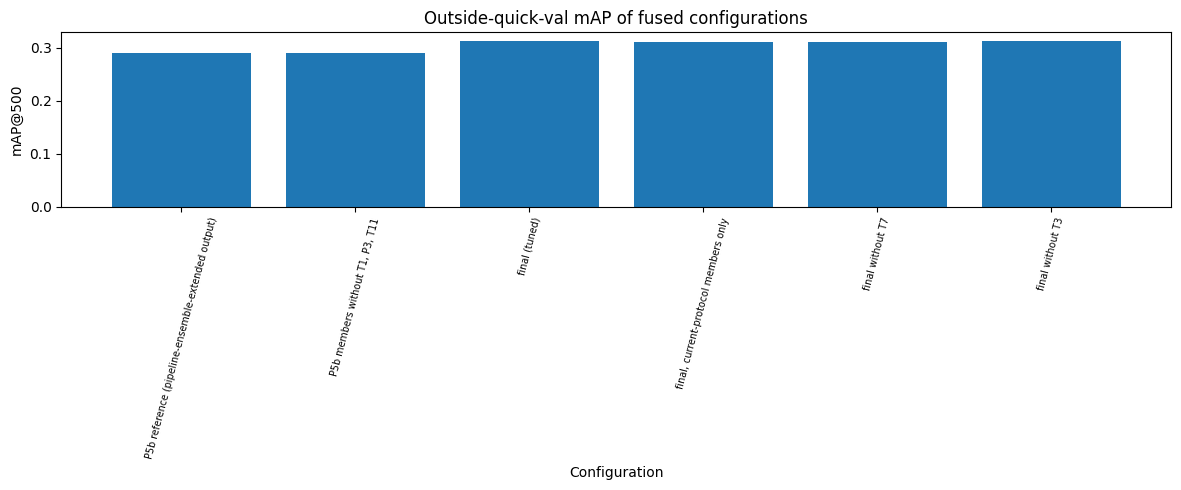

In [40]:
outside_rows = ablation.filter(pl.col("mAP_outside").is_not_null())
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.bar(range(outside_rows.height), outside_rows["mAP_outside"])
ax.set_xticks(range(outside_rows.height), labels=outside_rows["config"].to_list())
ax.tick_params(axis="x", labelrotation=75, labelsize="x-small")
ax.set_title("Outside-quick-val mAP of fused configurations")
ax.set_xlabel("Configuration")
ax.set_ylabel("mAP@500")
save_figure(fig, "ensemble_ablation", outside_rows.select("config", "n_members", "mAP_outside", "AP_small_outside"))

`result.json` is written again with the P5b reference on the same frames, the skipped ablation rows and the time the ablation finished (`finished_at` stays the time the run summary was first written).

In [41]:
result |= {
    "P5b_reference_mAP": p5b_reference_full["mAP"],
    "P5b_reference_mAP_outside_quick_val": p5b_reference_outside["mAP"],
    "skipped_ablation_rows": skipped_ablation_rows,
    "ablation_hours": round((time.time() - ablation_started) / 3600, 2),
    "ablation_finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
}
write_result(result)
session_hours = (time.time() - session_started) / 3600
print(f"result.json updated | skipped ablation rows {len(skipped_ablation_rows)} | session {session_hours:.2f} h")

result.json updated | skipped ablation rows 4 | session 10.70 h


## References

- Solovyev, Wang, Gabruseva. Weighted boxes fusion: ensembling boxes from different object detection models. arXiv:1910.13302 (WBF, class-wise fusion, confidence rescaling).
- `ensemble-boxes` 1.0.10 (`weighted_boxes_fusion`, `conf_type = "box_and_model_avg"`), MIT licence: https://github.com/ZFTurbo/Weighted-Boxes-Fusion
- Ren, He, Girshick, Sun. Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. arXiv:1506.01497 (members T2, T3, FC5, C3, P2 and the T3 / C3 views).
- Rezatofighi et al. Generalized Intersection over Union. arXiv:1902.09630 (GIoU box loss of T3 and C3).
- Lin, Goyal, Girshick, He, Dollar. Focal Loss for Dense Object Detection (RetinaNet). arXiv:1708.02002 (members RN, T6).
- Zhao et al. DETRs Beat YOLOs on Real-time Object Detection (RT-DETR). arXiv:2304.08069 (members RTD, T8).
- Ultralytics YOLO11 and RT-DETR (members T7, Y3, R3, C4, RTD, T8 and the T7 views, trained in their own kernels; not imported here), AGPL-3.0: https://github.com/ultralytics/ultralytics
- torchvision detection models (Faster R-CNN, RetinaNet members, trained in their own kernels; not imported here), BSD-3-Clause: https://github.com/pytorch/vision
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- Source runs (kernel sources): T2 `faster-rcnn-rpn-proposals`, T3 `faster-rcnn-giou`, T7 `yolo11s-1280-p2`, C4 `yolo11s-p2-combined`, C3 `faster-rcnn-combined` (and its views), R3 `yolo11s-1280-rerun`, T8 `rtdetr-l-queries-500`, T6 `retinanet-anchors-16-256`, P2 `pipeline-frame-offsets`, P1 `pipeline-inference` (views of T3 and T7), the legacy runs `faster-cnn-5`, `rt-detr-tuned-lr`, `yolo-3-1280`, `retinanet`, and the P5b output `pipeline-ensemble-extended` (reference row only); their reports are in `experiments/` and `EXPERIMENTS.md`. Only their saved output files are read; no member notebook code is used.
- Parent run P5b `pipeline-ensemble-extended` (report `experiments/dmnk1304/pipeline-ensemble-extended.md`): the protocol code, the member readers, the fusion function, the sequential evaluation, the weight-search rule, the result writer, the ablation table and the submission code are copied from `new-notebooks/pipeline-ensemble-extended.ipynb` (identical code to the pulled `notebooks/dmnk1304/pipeline-ensemble-extended.ipynb`).
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§5: the 4K val clip and the test resolutions; §9: test brightness).
- Planning document `SCOPE.md` (§3 principles, §3.10 decision rule, §3.14 final submissions, §3.15 priority-2 runs, §6 brief X1, §8 decisions 14, 17, 18, 20; findings F10, F66–F72, F81, F82, F92–F101, F104, F107–F116) as the source of the motivation numbers in the Overview.